In [1]:
from plot import *

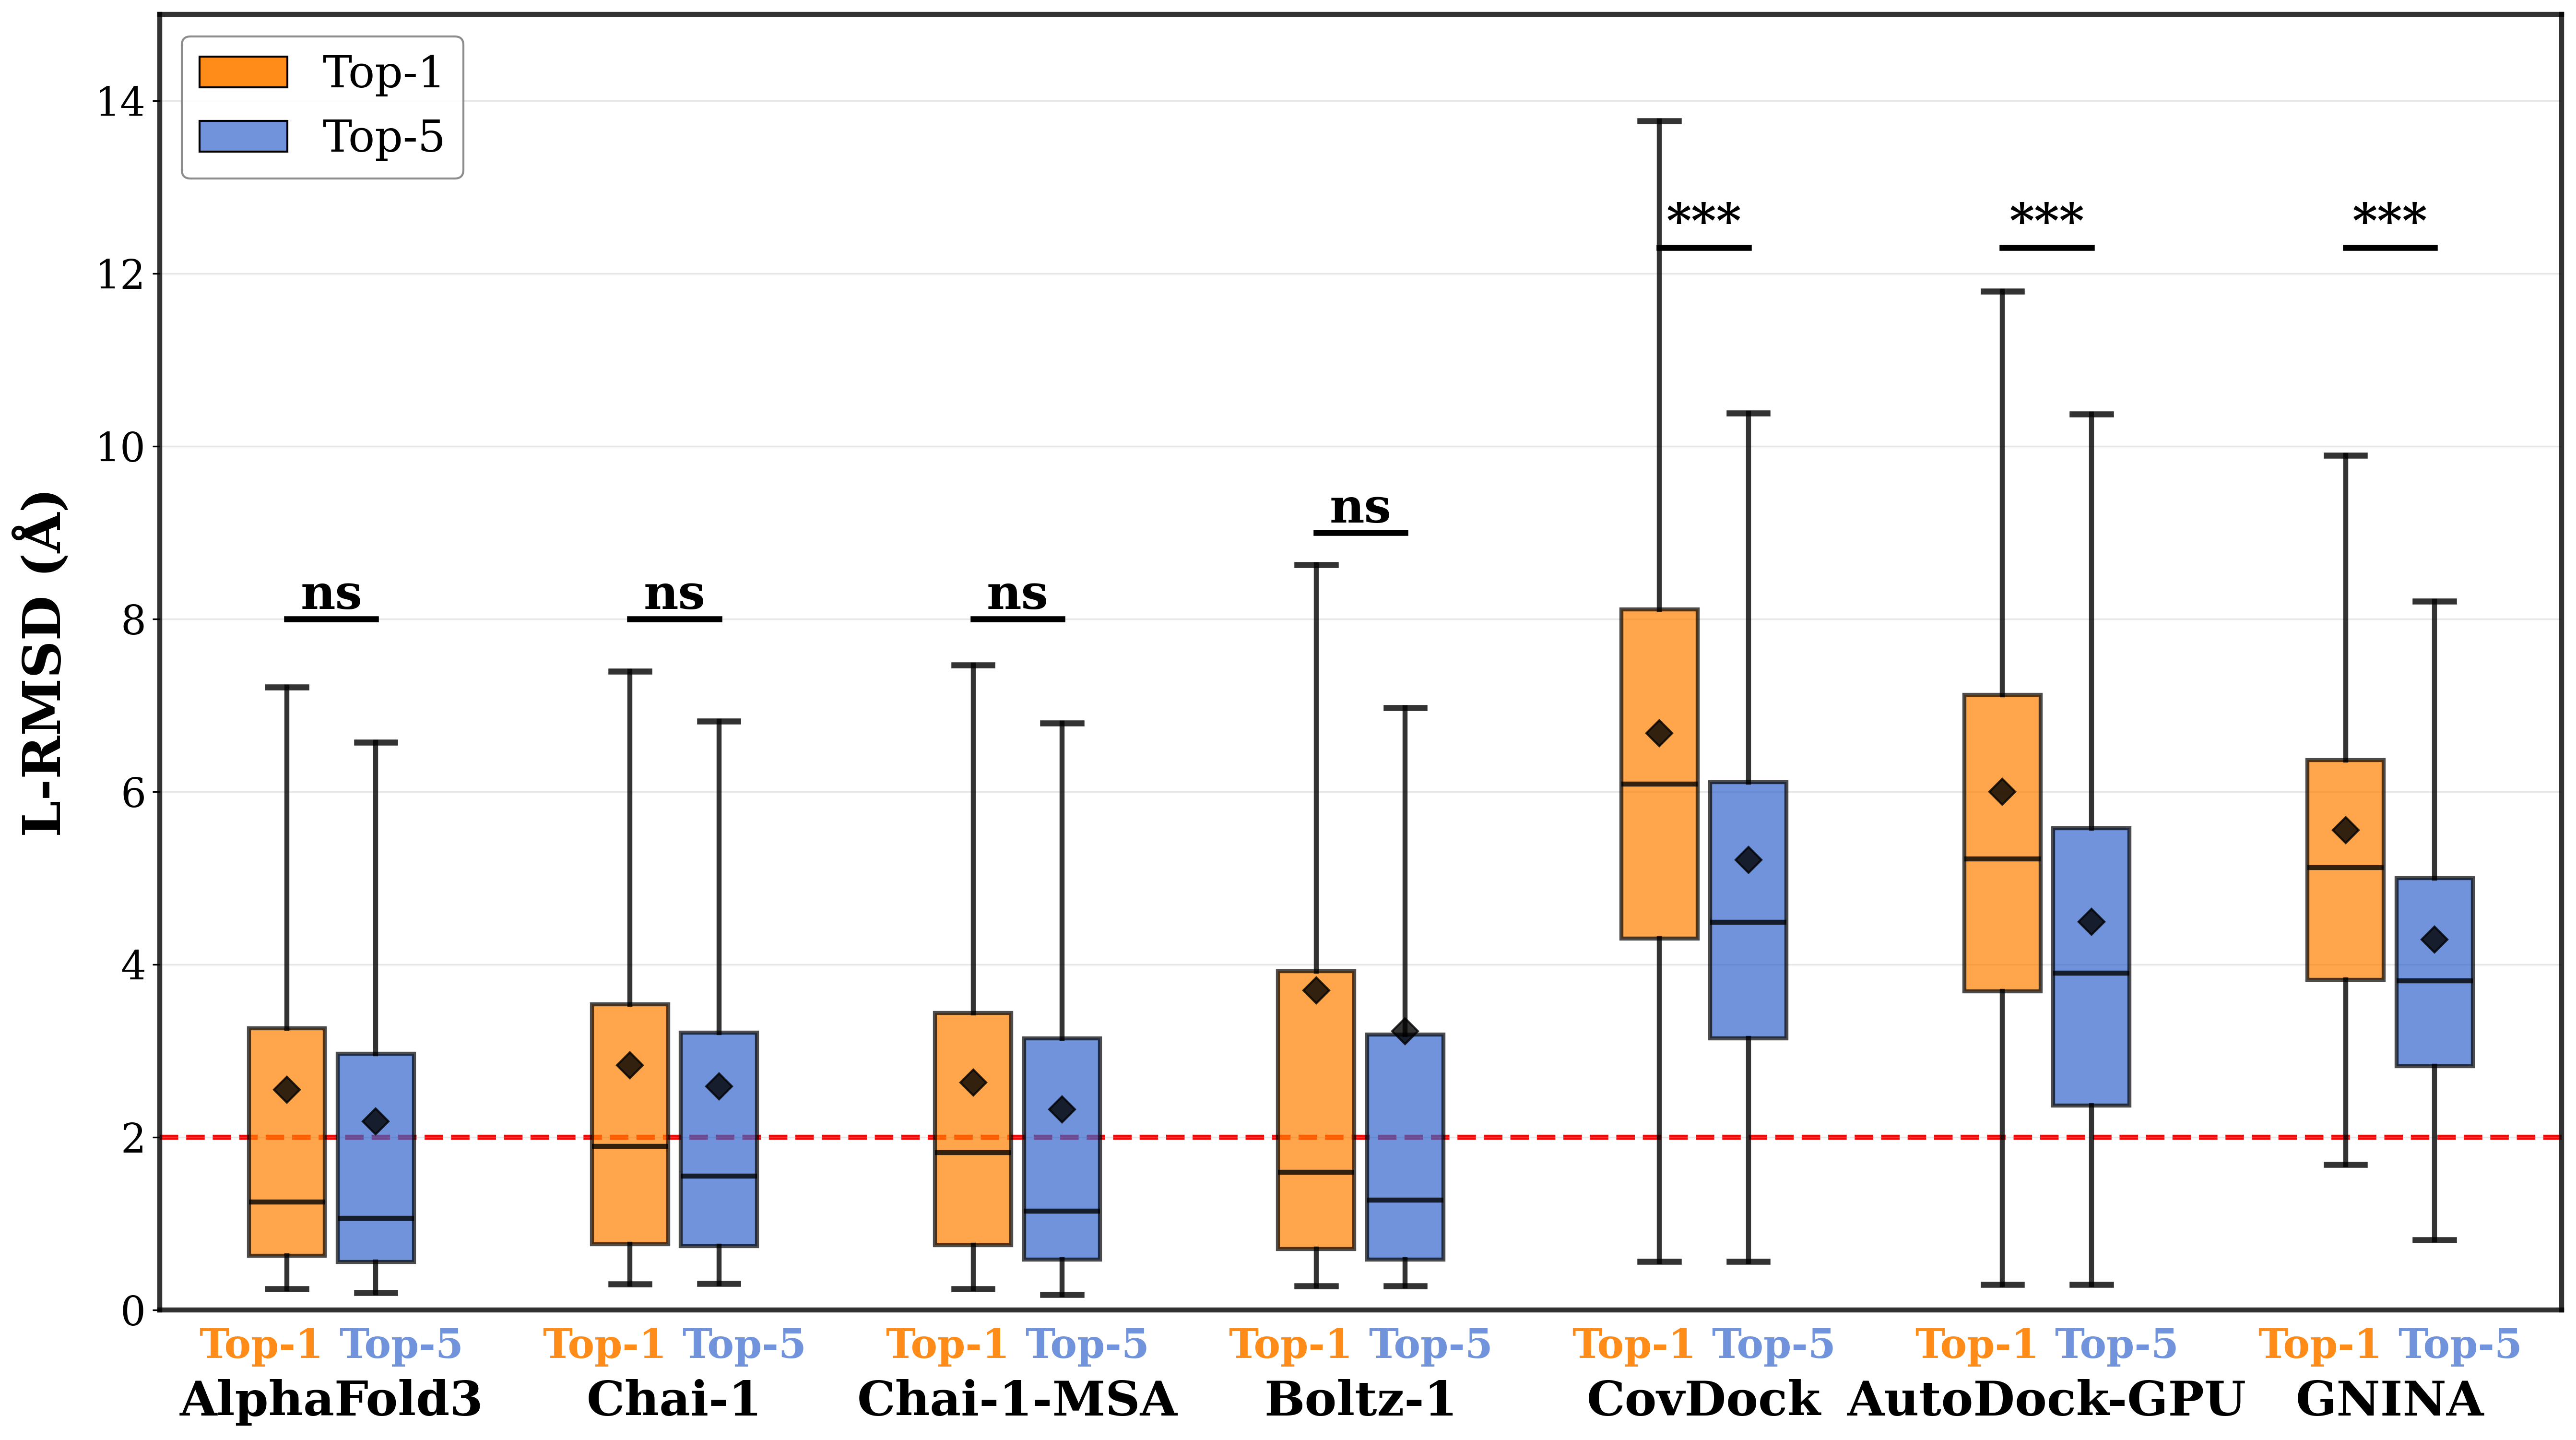

AlphaFold3           1pose      60.55% 2.55
AlphaFold3           5poses     65.60% 2.18
Chai-1               1pose      50.92% 2.83
Chai-1               5poses     58.06% 2.59
Chai-1-MSA           1pose      52.75% 2.63
Chai-1-MSA           5poses     62.67% 2.32
Boltz-1              1pose      59.87% 3.70
Boltz-1              5poses     63.16% 3.23
CovDock              1pose      4.08% 6.68
CovDock              5poses     12.76% 5.21
AutoDock-GPU         1pose      8.00% 6.00
AutoDock-GPU         5poses     16.50% 4.49
GNINA                1pose      2.38% 5.56
GNINA                5poses     6.19% 4.29


In [8]:
csv_file = "pdb_benchmark_RMSD.csv"  
methods = {
            "AlphaFold3": ['AF3_1pose_RMSD', 'AF3_5pose_RMSD'],
            "Chai-1": ['Chai-1_1pose_RMSD', 'Chai-1_5pose_RMSD'],
            "Chai-1-MSA": ['Chai-1_MSA_1pose_RMSD', 'Chai-1_MSA_5pose_RMSD'],
            "Boltz-1": ['Boltz-1_1pose_RMSD', 'Boltz-1_5pose_RMSD'],
            "CovDock": ['CovDock_1pose_RMSD_AlphaFold', 'CovDock_5pose_RMSD_AlphaFold'],
            "AutoDock-GPU": ['AutoDock_1pose_RMSD_AlphaFold', 'AutoDock_5pose_RMSD_AlphaFold'],
            "GNINA": ['GNINA_1pose_RMSD_AlphaFold', 'GNINA_5pose_RMSD_AlphaFold']
        }
output_dir = "rmsd_statistics/all_methods_comparison"
analyze_rmsd_statistics(
    csv_file=csv_file,
    methods=methods,
    output_dir=output_dir,
    rmsd_threshold=2,
    outward_ticks=False,
)

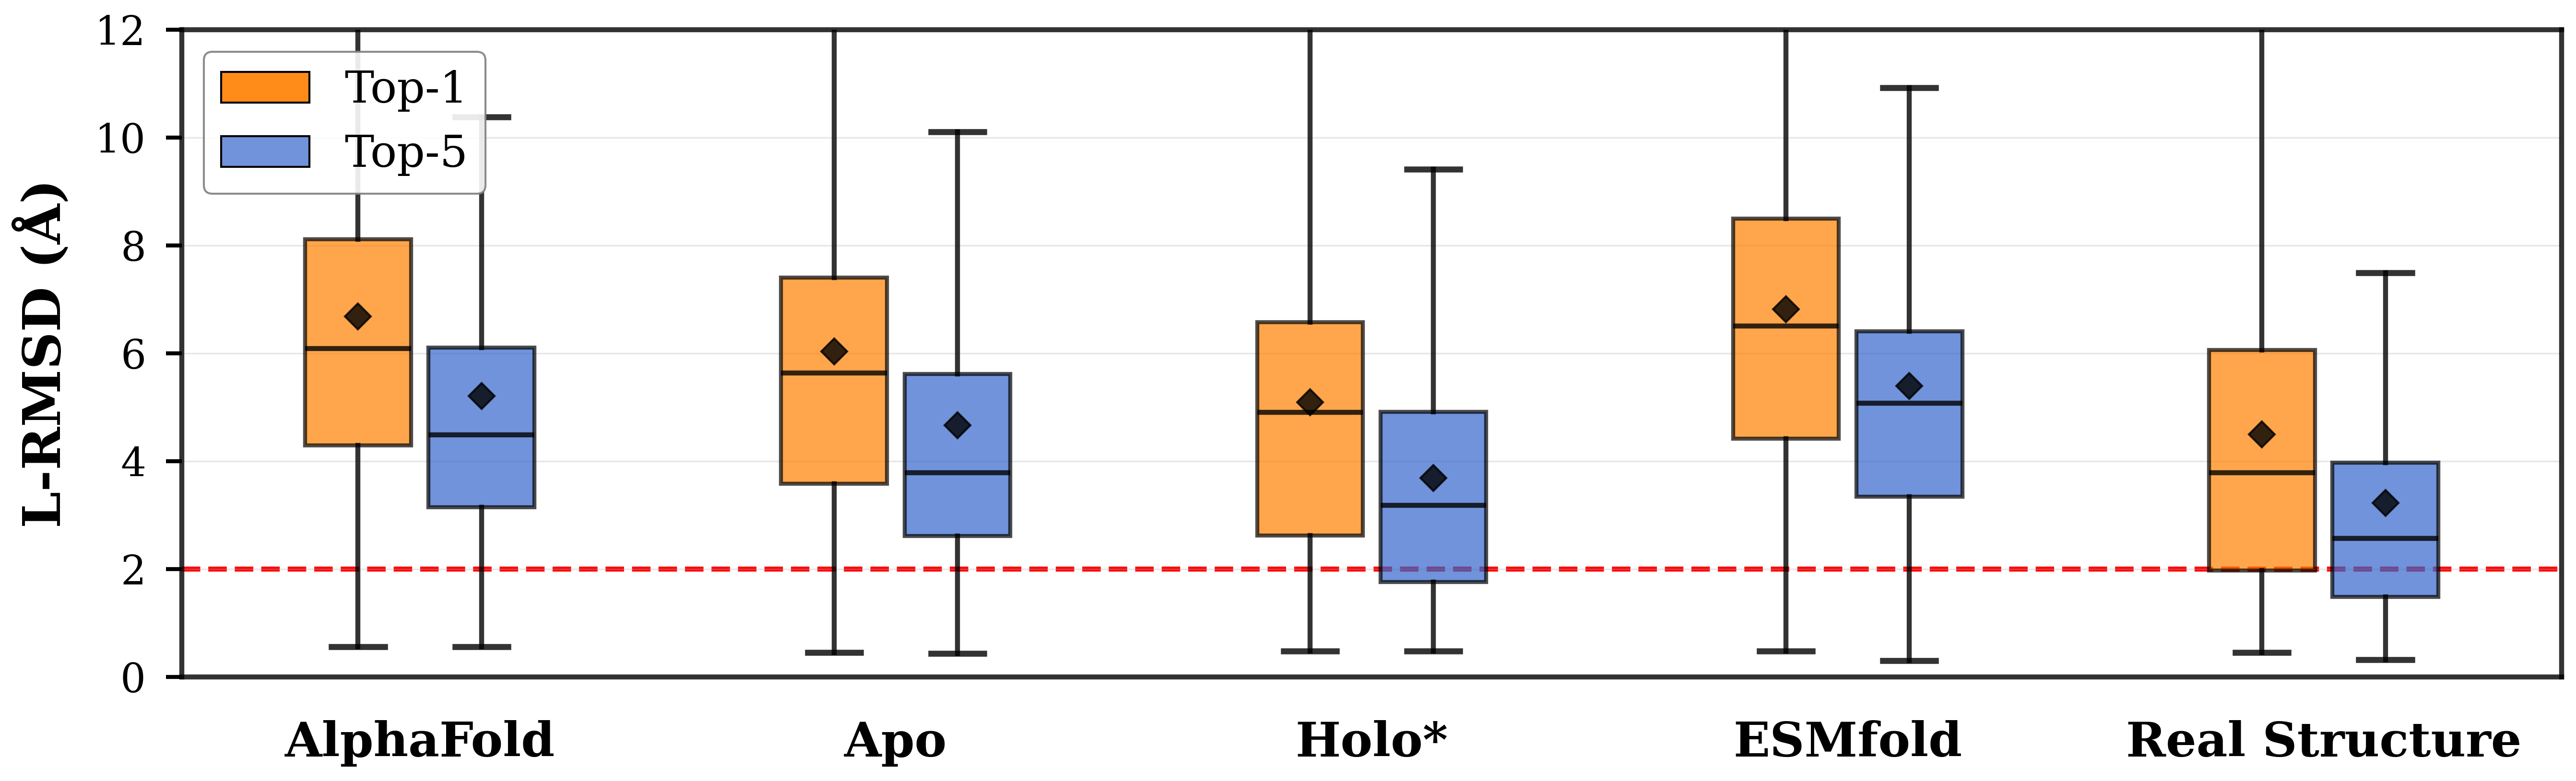

Boxplot saved to rmsd_statistics/Schrodinger_comparison


In [11]:
methods_Schrodinger = {
    "AlphaFold": ['CovDock_1pose_RMSD_AlphaFold', 'CovDock_5pose_RMSD_AlphaFold'],
    "Apo": ['CovDock_1pose_RMSD_Apo', 'CovDock_5pose_RMSD_Apo'],
    "Holo*": ['CovDock_1pose_RMSD_Holo', 'CovDock_5pose_RMSD_Holo'],
    "ESMfold": ['CovDock_1pose_RMSD_ESMFold', 'CovDock_5pose_RMSD_ESMFold'],
    "Real Structure": ['CovDock_1pose_RMSD', 'CovDock_5pose_RMSD']
}

# 创建输出目录
# 创建输出目录
output_dir = "rmsd_statistics/Schrodinger_comparison"

# 运行分析
results = analyze_rmsd_statistics_(
    csv_file=csv_file,
    methods=methods_Schrodinger,
    output_dir=output_dir,
    rmsd_threshold=2,
    fig_size=(18, 6),   
)


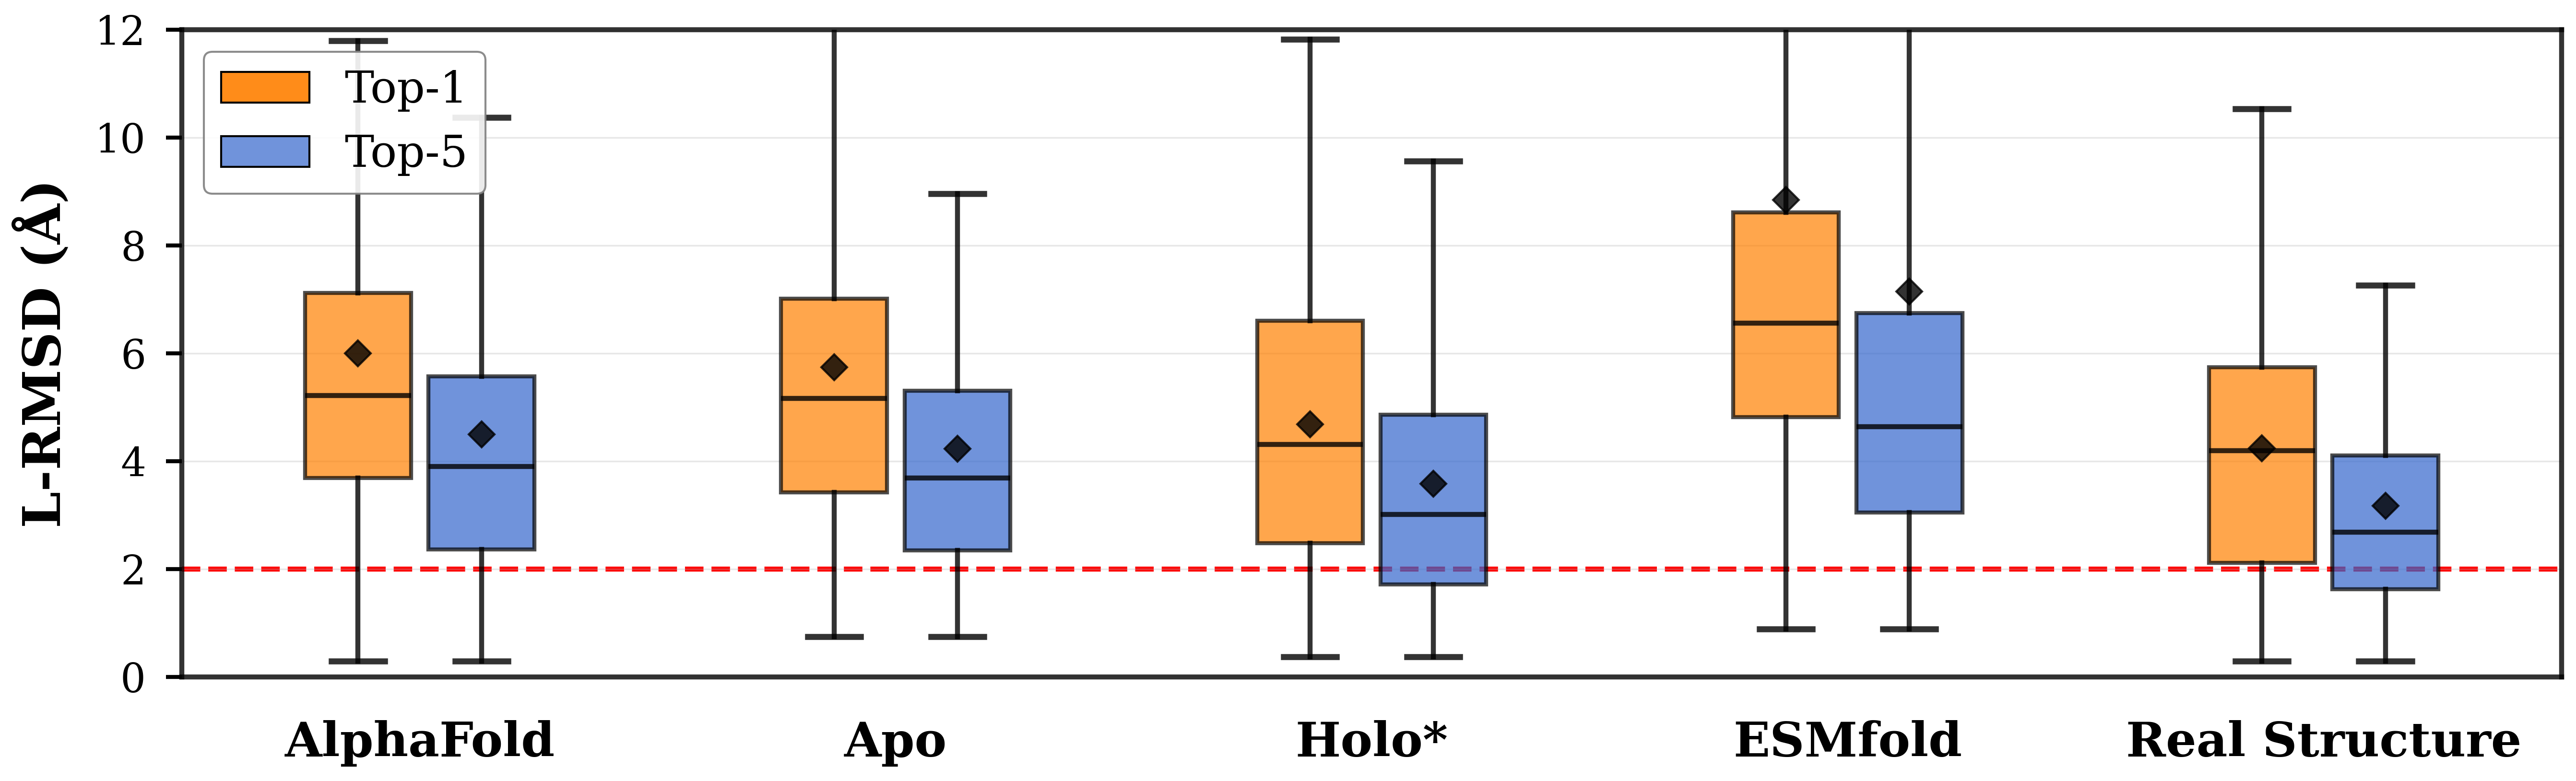

Boxplot saved to rmsd_statistics/Autodock_comparison


In [12]:
methods_Autodock = {
    "AlphaFold": ['AutoDock_1pose_RMSD_AlphaFold', 'AutoDock_5pose_RMSD_AlphaFold'],
    "Apo": ['AutoDock_1pose_RMSD_Apo', 'AutoDock_5pose_RMSD_Apo'],
    "Holo*": ['AutoDock_1pose_RMSD_Holo', 'AutoDock_5pose_RMSD_Holo'],
    "ESMfold": ['AutoDock_1pose_RMSD_ESMFold', 'AutoDock_5pose_RMSD_ESMFold'],
    "Real Structure": ['AutoDock_1pose_RMSD', 'AutoDock_5pose_RMSD'],
}

# 创建输出目录
# 创建输出目录
output_dir = "rmsd_statistics/Autodock_comparison"

# 运行分析
results = analyze_rmsd_statistics_(
    csv_file=csv_file,
    methods=methods_Autodock,
    output_dir=output_dir,
    rmsd_threshold=2,
    fig_size=(18, 6),        
)


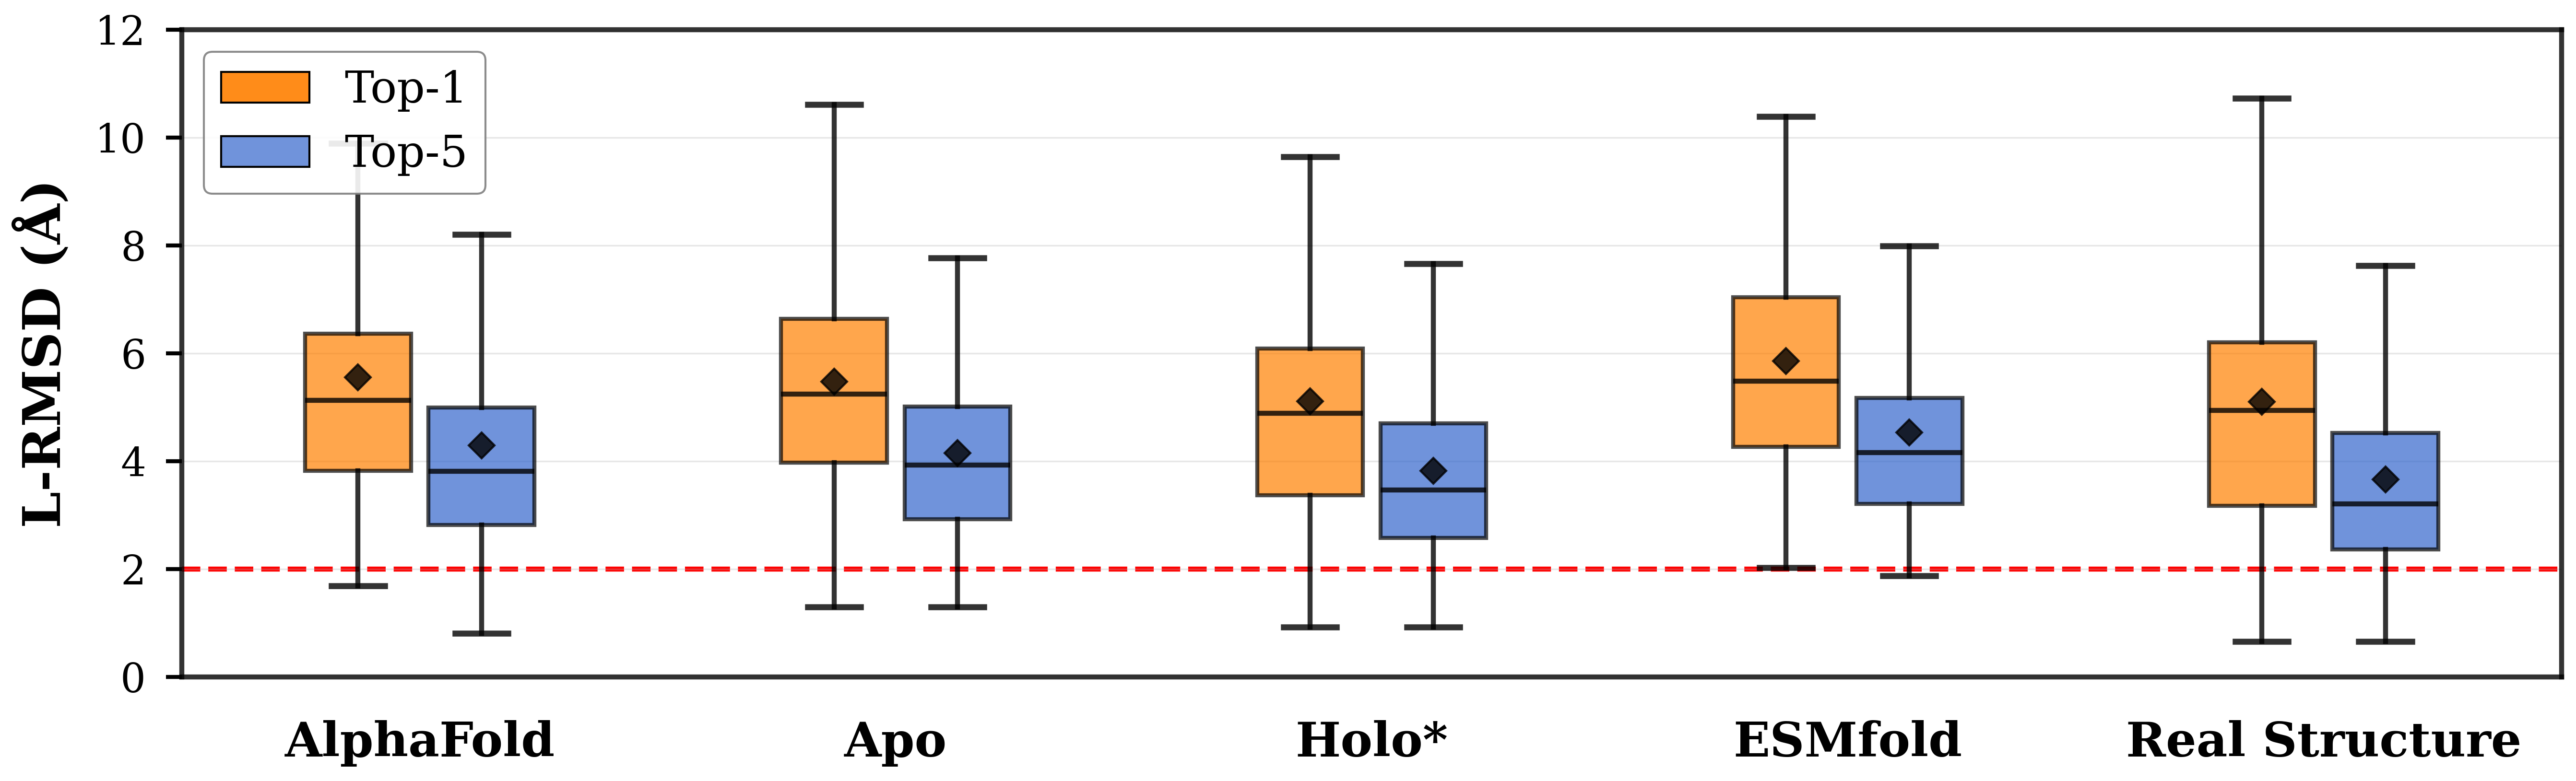

Boxplot saved to rmsd_statistics/Gnina_comparison


In [14]:
methods_Gnina = {
    "AlphaFold": ['GNINA_1pose_RMSD_AlphaFold', 'GNINA_5pose_RMSD_AlphaFold'],
    "Apo": ['GNINA_1pose_RMSD_Apo', 'GNINA_5pose_RMSD_Apo'],
    "Holo*": ['GNINA_1pose_RMSD_Holo', 'GNINA_5pose_RMSD_Holo'],
    "ESMfold": ['GNINA_1pose_RMSD_ESMFold', 'GNINA_5pose_RMSD_ESMFold'],
    "Real Structure": ['GNINA_1pose_RMSD', 'GNINA_5pose_RMSD'],
}

# 创建输出目录
# 创建输出目录
output_dir = "rmsd_statistics/Gnina_comparison"

# 运行分析
results = analyze_rmsd_statistics_(
    csv_file=csv_file,
    methods=methods_Gnina,
    output_dir=output_dir,
    rmsd_threshold=2,
    fig_size=(18, 6),     
)


Warhead names for manual annotation:
----------------------------------------
Segment 1: Aldehyde - Success rate: 85.4%
Segment 2: Vinyl Carbonyl - Success rate: 69.7%
Segment 3: Ketone - Success rate: 72.7%
Segment 4: Halomethyl Carbonyl - Success rate: 34.4%
Segment 5: other - Success rate: 54.8%
Segment 6: Beta Lactam - Success rate: 53.3%
Segment 7: Boronic Acid - Success rate: 69.2%
Segment 8: Nitrile - Success rate: 90.0%
Segment 9: Ester - Success rate: 70.0%


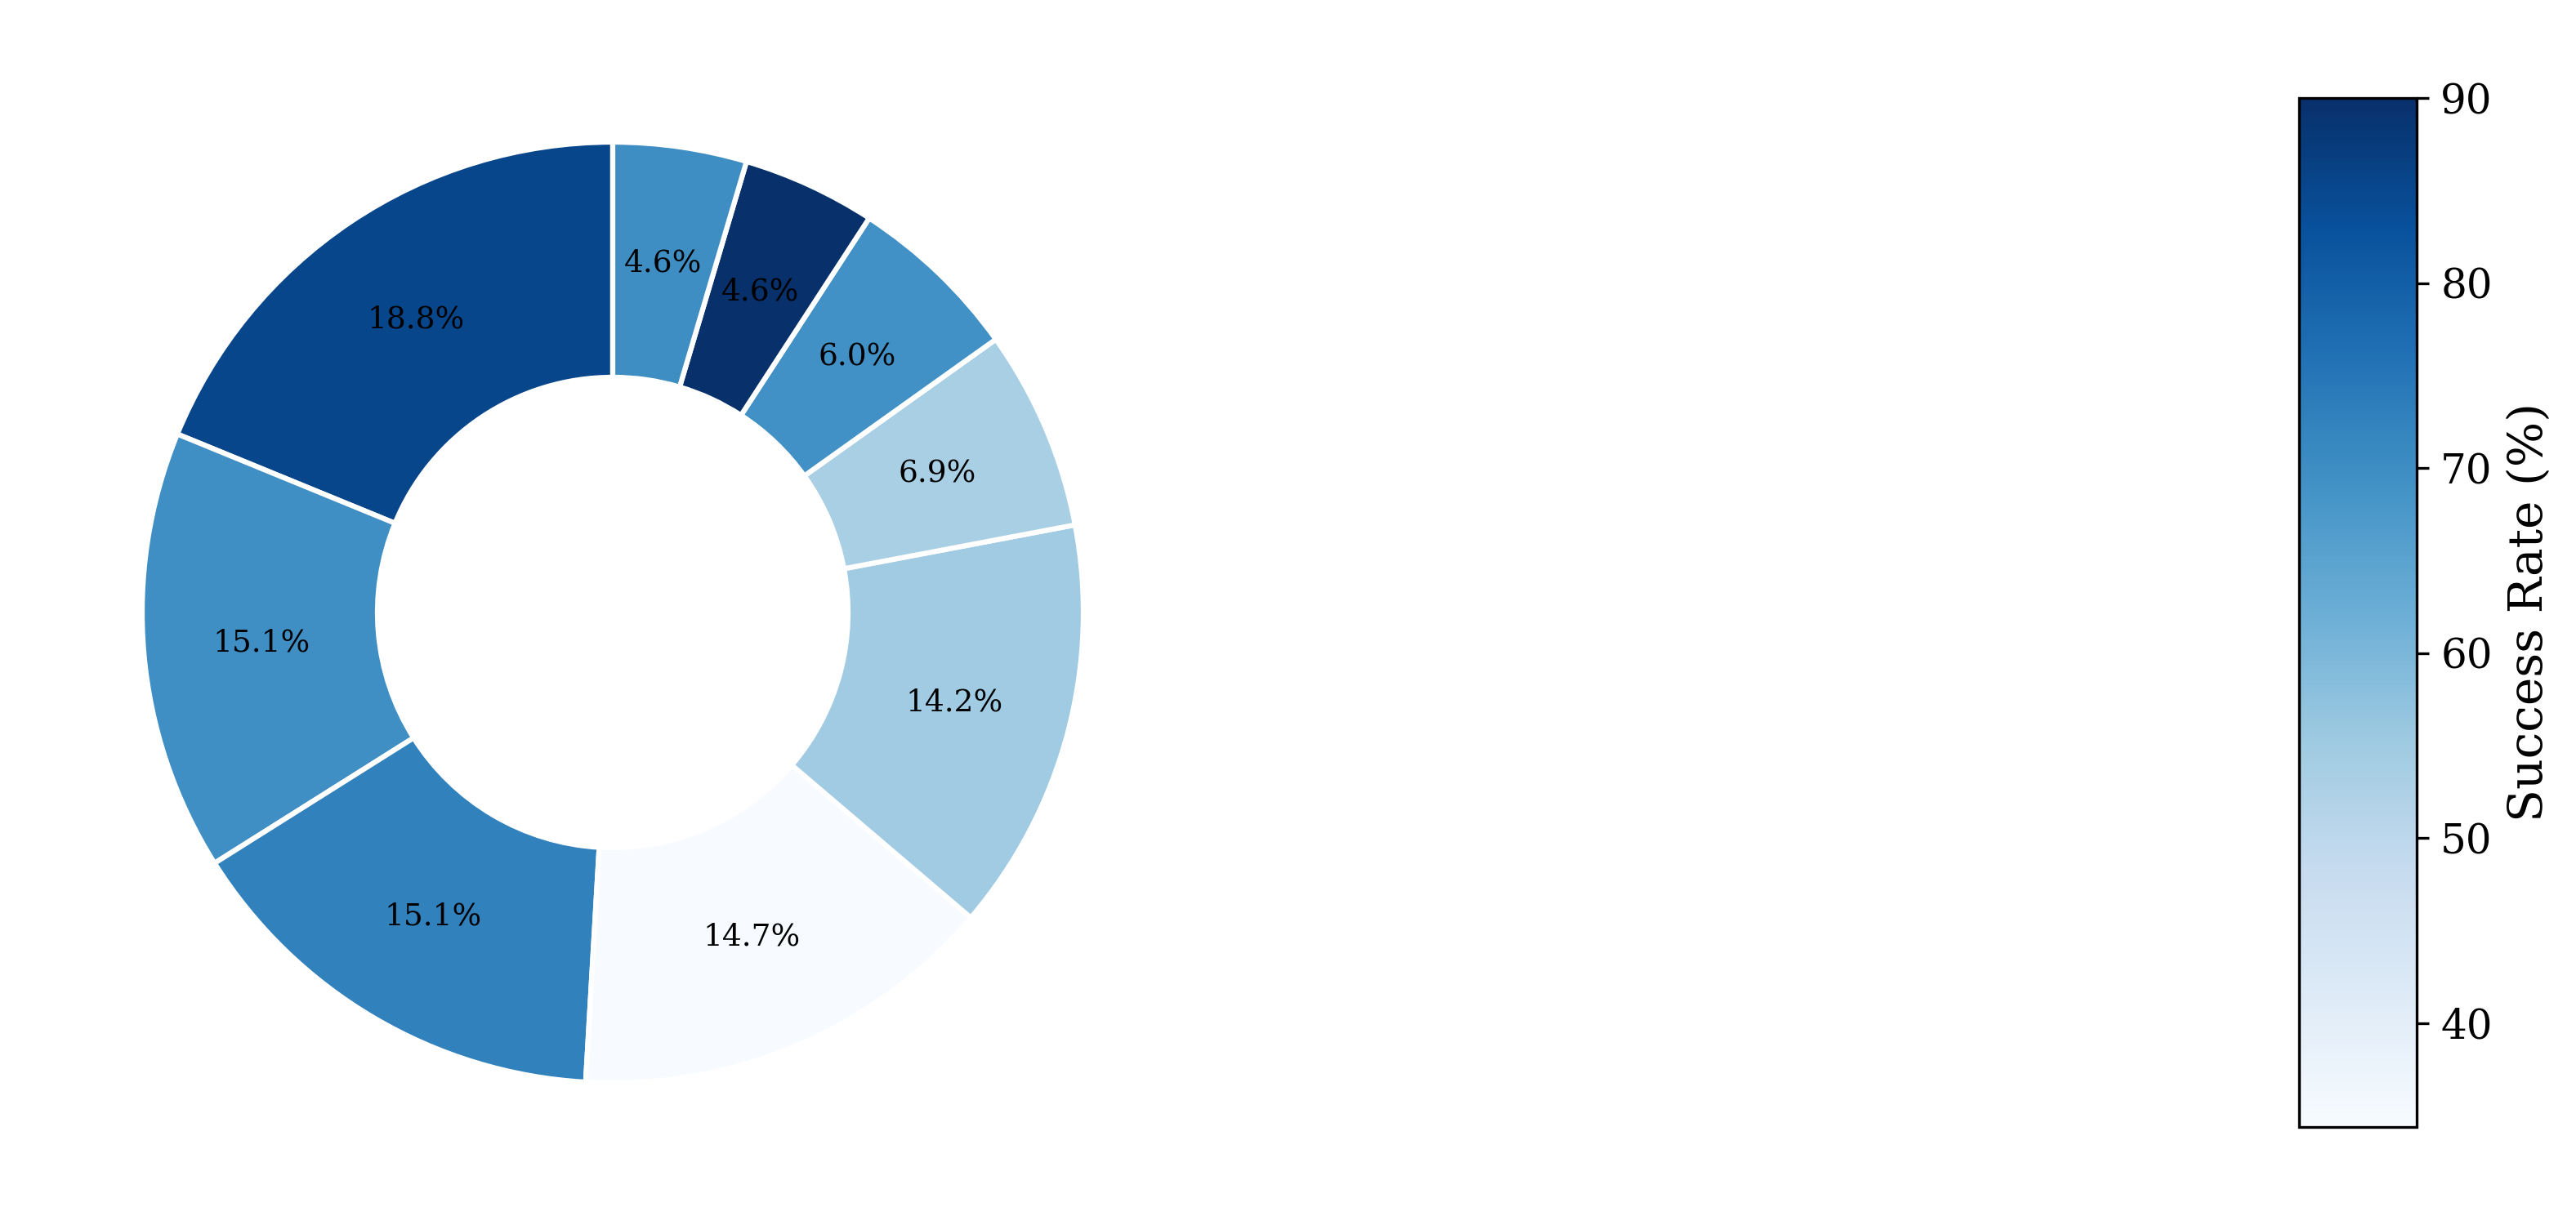

In [18]:
rmsd_csv_file = "pdb_benchmark_RMSD.csv"
warhead_csv_file = "pdb_benchmark.csv"
rmsd_col = 'AF3_5pose_RMSD'
output_dir = "AF3_warhead_analysis"

data_rmsd = pd.read_csv(rmsd_csv_file)
data_warhead = pd.read_csv(warhead_csv_file)
data = pd.merge(data_rmsd, data_warhead, on='pdb_id', how='left')
result = analyze_af3_success_rate(data, rmsd_col, rmsd_threshold=2.0, min_count=10)
plot_af3_warhead_pie(result, output_dir)

/tmp/ipykernel_884200/3515146752.py:31: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 750x750 with 0 Axes>

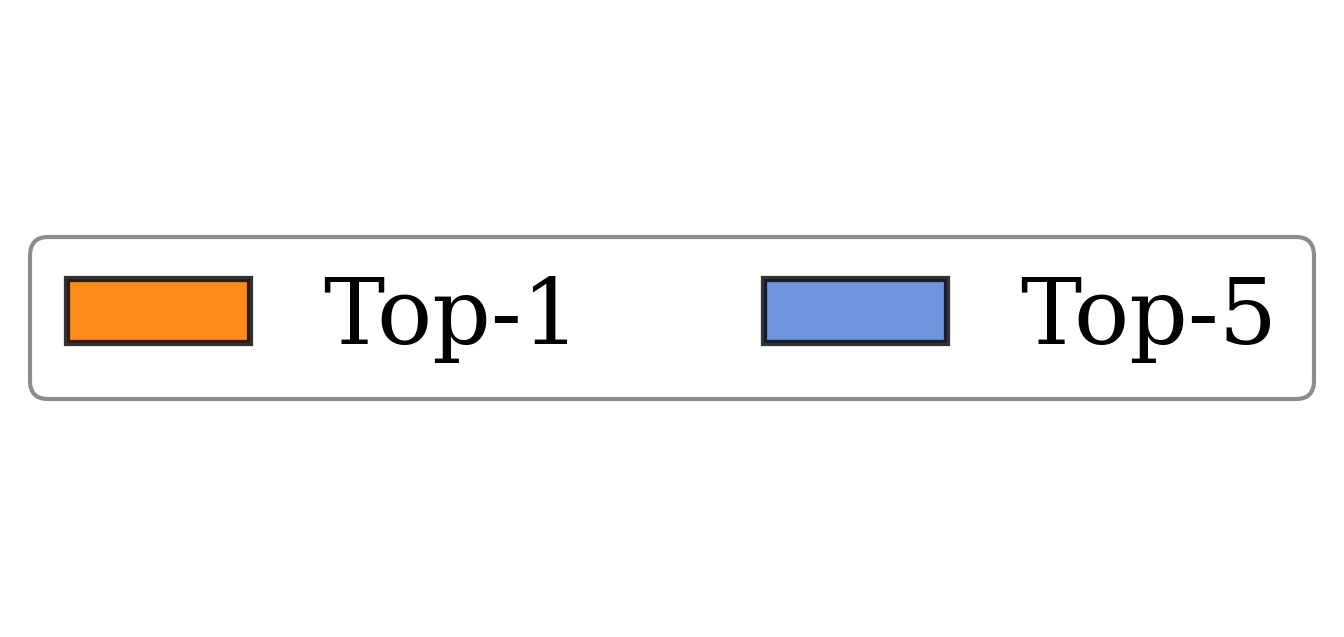

In [19]:
output_dir = "rmsd_statistics/legend"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 定义颜色
pose_colors = {
    "Top-5": (0.2, 0.4, 0.8, 0.7),  # 蓝色
    "Top-1": (1.0, 0.5, 0.0, 0.9)    # 橙色
}

# 创建只有图例的图像
plt.figure(figsize=(2.5, 2.5))
black_semi = (0, 0, 0, 0.8)

# 创建图例元素
legend_elements = [
    Patch(facecolor=pose_colors["Top-1"], edgecolor=black_semi, linewidth=1.5, label='Top-1'),
    Patch(facecolor=pose_colors["Top-5"], edgecolor=black_semi, linewidth=1.5, label='Top-5')
]

# 创建一个空白的轴对象
fig, ax = plt.subplots(figsize=(2.5, 2.5))
ax.set_axis_off()  # 隐藏坐标轴

# 添加图例 - 使用ncol=1使图例分成两行
leg = ax.legend(handles=legend_elements, loc='center', 
               frameon=True, edgecolor='gray', framealpha=0.9, 
               fontsize=22, ncol=2) 

# 调整图例位置
plt.tight_layout()
plt.savefig(f"{output_dir}/legend.svg", format='svg', bbox_inches='tight')
